# 로컬 트레이싱과 지연

**이 노트북에서 할 일**

1. 판정 요청 한 번을 세 단계로 나누고 단계마다 걸린 초를 잽니다.
2. 단계 기록과 사용량을 실행 추적 한 건으로 묶어 노트북 안에 남깁니다.
3. 같은 요청을 스트리밍으로 받아 첫 토큰 도착 시간과 전체 지연을 가릅니다.
4. 근거 문서가 더 긴 사례로 바꿔 같은 기록을 한 번 더 남깁니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 세 번이고 임베딩 요청은 없습니다.
예상 비용은 미화 0.01달러 아래이고 실제 청구 금액과는 다를 수 있습니다.
LangSmith 키는 쓰지 않고 실행 추적을 서버로 보내지 않습니다.

걸린 시간은 기기·네트워크·실행 때에 따라 달라집니다.
그래서 이 노트북에 찍힌 초 값은 여러분 실행과 다를 수 있습니다.
읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
판정 요청 한 번을 단계로 나누고 실행 추적 한 건으로 묶는 자리입니다.
7절은 스트리밍으로 첫 토큰 도착 시간을 잽니다.
8절은 값 바꿔 보기이고 7절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 사례 Q002 근거 문서와 답에서 파란 상자 1단계 요청 글 만들기 build_judge_prompt, 보라 상자 2단계 모델 요청 gpt-5.4-mini invoke, 파란 상자 3단계 JSON 읽기 json.loads를 차례로 지나 노란 상자 실행 추적 한 건 단계 기록 셋 전체 걸린 초 입력 캐시 입력 출력 토큰 수로 이어지고, 보라 상자에서 노란 상자로 사용량이라고 적힌 화살표가 따로 가며, 오른쪽 회색 상자에 단계 앞뒤 시각 넷을 한 셀 안에서 적음 time.perf_counter가 적힌 그림](attachment:05-1-판정-요청-한-번의-실행-추적.png)

위에서 아래로 읽습니다. 초록 상자 사례 Q002가 세 단계를 차례로 지납니다.
파란 상자 둘은 노트북 안에서 하는 일이고 가운데 보라 상자만 평가 모델에 보내는 요청입니다.
맨 아래 노란 상자가 단계 기록 셋과 사용량을 묶은 실행 추적 한 건입니다.
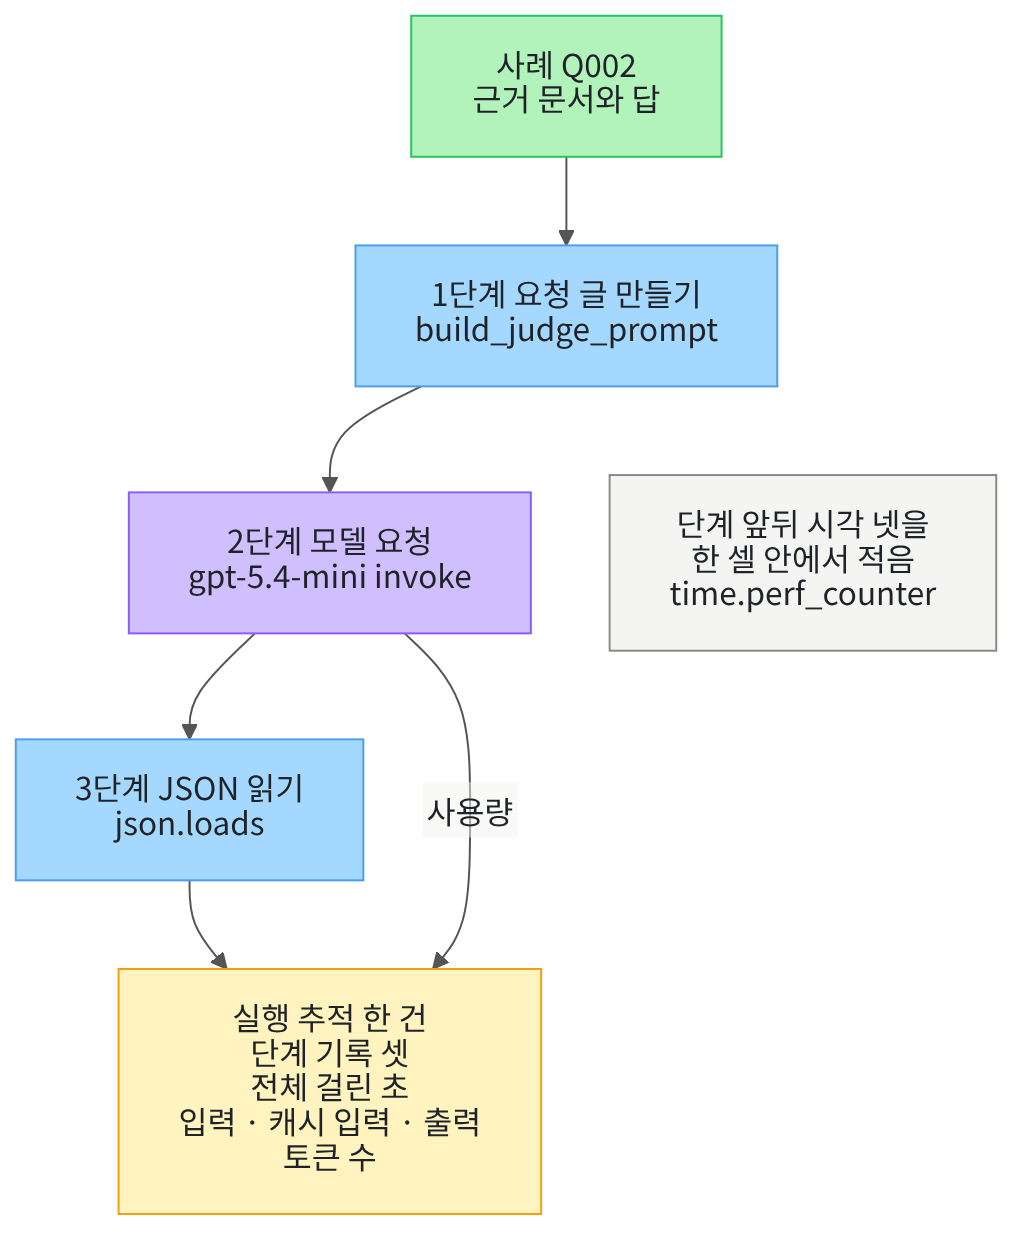

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 02절 함수 하나를 도구 파일에서 가져옵니다.
이름 `time`은 걸린 시간을 잴 때 씁니다(Ch 6 06절).

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `build_judge_prompt()`만 가져옵니다.

In [2]:
# 자료 읽기·시간 재기·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import os
import time

from langchain.chat_models import init_chat_model

# Ch 15 02절에서 배운 함수 하나를 도구 파일에서 가져옵니다
from rag_tools import build_judge_prompt

print("불러온 이름:", "json", "os", "time", "init_chat_model")

불러온 이름: json os time init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os time init_chat_model`로 이름 네 개를 불러왔습니다.
도구 파일에서 가져온 함수 `build_judge_prompt`는 출력하지 않습니다.
이 함수는 02절에서 쓰던 인자 그대로입니다.

## 2. 키와 모델 준비

이 절도 02~04절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 04절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 글과 걸린 시간이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 판정 요청 한 건

이 절은 02절에서 받은 근거 충실도 판정 한 번을 다시 보냅니다.
이번에는 판정 점수보다 요청 한 번이 어디에서 시간을 쓰는지 봅니다.

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~04절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 04절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.
이 절에서 쓸 첫 사례와 마지막 사례도 꺼내 둡니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록을 만들고 첫 사례와 마지막 사례를 꺼냅니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
first_case = cases[0]
last_case = cases[2]
print("평가 사례 수:", len(cases))
print("첫 사례와 마지막 사례:", first_case["qid"], last_case["qid"])
print("근거 문서 글자 수:", len(first_case["context"]), len(last_case["context"]))

평가 사례 수: 3
첫 사례와 마지막 사례: Q002 Q090
근거 문서 글자 수: 3020 4936


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `첫 사례와 마지막 사례: Q002 Q090`이 이 절에서 쓸 두 사례입니다.
출력 줄 `근거 문서 글자 수: 3020 4936`처럼 Q090의 근거 문서가 더 깁니다.

4~7절은 사례 Q002 하나로 요청을 보냅니다.
8절 값 바꿔 보기에서 근거 문서가 더 긴 Q090으로 바꿉니다.
다음 셀은 02절 근거 충실도의 판정 머리글을 다시 적습니다.

In [7]:
# 02절 근거 충실도의 두 칸 짝과 판정 머리글 rag-judge-v1.0.0을 다시 적습니다
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_version = "rag-judge-v1.0.0"
judge_head = ground_rule + "\n" + output_rule
print("판 이름:", judge_version)
print("머리글:")
print(judge_head)

판 이름: rag-judge-v1.0.0
머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판 이름: rag-judge-v1.0.0`은 02절이 붙인 판 이름입니다.
라벨 줄 `머리글:` 아래 두 줄이 기준 문장과 출력 모양입니다.
02절 근거 충실도 머리글과 글자까지 같은 글입니다.

이 절은 머리글 한 판만 씁니다.
판정 점수가 맞는지는 02~04절에서 봤으니 이 절에서는 다시 따지지 않습니다.

## 4. 세 단계로 나누어 시각 적기

02절 함수 `build_judge_prompt()`는 머리글과 사례 두 칸으로 판정 요청 글을 만들었습니다.
02절 함수 `judge_once()`는 그 글을 모델에 보내고 받은 JSON 글을 읽었습니다.
그래서 판정 한 번은 요청 글 만들기, 모델 요청, JSON 읽기의 세 단계입니다.
다음 셀은 세 단계의 이름을 차례대로 적습니다.

In [8]:
# 판정 요청 한 번을 나눌 세 단계의 이름을 차례대로 적습니다
step_names = ["요청 글 만들기", "모델 요청", "JSON 읽기"]
print("단계 이름:", step_names)
print("단계 수:", len(step_names))

단계 이름: ['요청 글 만들기', '모델 요청', 'JSON 읽기']
단계 수: 3


**결과 읽기** — 출력 줄 `단계 이름:` 뒤 목록이 세 단계의 차례입니다.
출력 줄 `단계 수: 3`처럼 판정 요청 한 번을 세 단계로 나눕니다.

단계마다 걸린 시간을 재려면 단계와 단계 사이의 시각을 적어 둡니다.
Ch 6 06절 함수 `timed_invoke()`는 요청 앞뒤 두 시각만 적었습니다.
이번에는 세 단계의 앞뒤에 시각 넷을 적습니다.
시각은 Ch 6 06절처럼 `time.perf_counter()`로 읽고, 두 값을 빼면 그 사이에 걸린 초입니다.

네 시각은 모두 한 셀 안에서 적습니다.
셀을 나누어 실행하면 셀과 셀 사이에 기다린 시간도 함께 들어가기 때문입니다.
그래서 모델 요청과 JSON 읽기는 02절 `judge_once()`를 부르지 않고 셀 안에 풀어 적습니다.
다음 셀은 사례 Q002의 판정 요청 한 번을 보냅니다.

In [9]:
# 사례 Q002의 판정 요청 한 번을 세 단계로 나누고 단계 사이마다 시각을 적습니다(모델 요청 1번)
time_marks = [time.perf_counter()]
prompt_text = build_judge_prompt(judge_head, ground_pair, first_case)
time_marks.append(time.perf_counter())
reply = model.invoke(prompt_text)
time_marks.append(time.perf_counter())
verdict = json.loads(reply.text)
time_marks.append(time.perf_counter())
print("적은 시각 수:", len(time_marks))
print("점수:", verdict["score"], "| 까닭:", verdict["reason"])

적은 시각 수: 4
점수: 1 | 까닭: 근거 문서 4항에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.


**결과 읽기** — 출력 줄 `적은 시각 수: 4`는 세 단계의 앞뒤에 적은 시각의 수입니다.
출력 줄 `점수:` 뒤가 평가 모델의 판정이고, 이 셀에서 모델 요청이 한 번 나갔습니다.

이번 실행에서는 점수 1을 받았습니다.
까닭은 근거 문서 4항에 도서 7권과 14일이 적혀 있다는 문장이었습니다.
까닭 글은 모델이 쓴 문장이라 실행마다 달라질 수 있습니다.

목록 `time_marks`에는 시각 넷이 차례로 들어 있습니다.
이웃한 두 시각을 빼면 그 사이 단계에 걸린 초가 나옵니다.
다음 셀은 이 계산을 함수 하나로 묶습니다.

In [10]:
# 단계 이름 목록과 시각 목록으로, 단계마다 걸린 초를 담은 단계 기록 목록을 만듭니다
def make_steps(names, marks):
    steps = []
    for i in range(len(names)):
        seconds = round(marks[i + 1] - marks[i], 3)
        steps.append({"단계": names[i], "걸린 초": seconds})
    return steps

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_steps`는 단계 이름 목록과 시각 목록을 받습니다.
단계 번호 `i`마다 뒤 시각 `marks[i + 1]`에서 앞 시각 `marks[i]`를 뺍니다.
뺀 값은 `round()`로 소수 셋째 자리까지 남겨 1000분의 1초까지 봅니다.
결과는 단계 이름과 걸린 초를 담은 딕셔너리를 차례로 모은 목록입니다.

이 딕셔너리 하나를 단계 기록(span)이라고 부릅니다.
하루 일정표에서 일 하나의 이름과 걸린 시간을 적은 한 줄과 같습니다.
이 절에서는 함수 `make_steps`가 만든 목록의 딕셔너리 하나하나가 단계 기록입니다.
다음 셀은 사례 Q002 요청의 단계 기록을 만듭니다.

In [11]:
# 사례 Q002 요청의 단계 기록 셋을 만들어 단계마다 걸린 초를 봅니다
first_steps = make_steps(step_names, time_marks)
print("단계 | 걸린 초")
for step in first_steps:
    print(step["단계"], "|", step["걸린 초"])

단계 | 걸린 초
요청 글 만들기 | 0.0
모델 요청 | 0.993
JSON 읽기 | 0.0


**결과 읽기** — 라벨 줄 `단계 | 걸린 초` 아래 세 줄이 단계 기록 셋입니다.
줄의 차례는 출력 줄 `단계 이름:`의 차례와 같습니다.

이번 실행에서는 요청 글 만들기와 JSON 읽기가 `0.0`초, 모델 요청이 `0.993`초였습니다.
값 `0.0`은 0.0005초보다 짧아 소수 셋째 자리에서 0이 되었다는 뜻입니다.
두 단계는 노트북 안에서 글을 잇고 읽는 일이고, 모델 요청은 서버에 다녀오는 일입니다.
새 커널로 두 번 실행했을 때 두 단계는 두 번 모두 `0.0`초였고 모델 요청의 초 값만 달랐습니다.

## 5. 가장 긴 단계와 전체 지연

단계가 많아지면 표를 눈으로 훑기보다 가장 긴 단계를 코드로 찾는 편이 낫습니다.
다음 셀은 단계 기록을 처음부터 끝까지 보며 더 긴 단계를 남기는 함수입니다.

In [12]:
# 단계 기록 목록에서 걸린 초가 가장 큰 단계의 이름을 찾습니다
def longest_step(steps):
    longest = steps[0]
    for step in steps:
        if step["걸린 초"] > longest["걸린 초"]:
            longest = step
    return longest["단계"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `longest_step`은 첫 단계 기록을 가장 긴 것으로 두고 시작합니다.
다음 단계의 걸린 초가 더 크면 그 단계로 바꿉니다.
끝까지 본 뒤 남은 단계의 이름을 냅니다.

다음 셀은 가장 긴 단계와 요청 한 번 전체에 걸린 초를 봅니다.
전체는 첫 시각 `time_marks[0]`부터 마지막 시각 `time_marks[-1]`까지입니다.
목록 자리 `-1`은 맨 끝 자리를 가리킵니다.

In [13]:
# 가장 긴 단계를 찾고, 첫 시각부터 마지막 시각까지 요청 한 번 전체에 걸린 초를 봅니다
first_longest = longest_step(first_steps)
first_total = round(time_marks[-1] - time_marks[0], 3)
print("가장 긴 단계:", first_longest)
print("전체 걸린 초:", first_total)

가장 긴 단계: 모델 요청
전체 걸린 초: 0.994


**결과 읽기** — 출력 줄 `가장 긴 단계: 모델 요청`으로 세 단계 가운데 모델 요청이 가장 길었습니다.
출력 줄 `전체 걸린 초:` 뒤가 첫 시각부터 마지막 시각까지의 초입니다.

이번 실행에서 전체 걸린 초는 `0.994`초로 모델 요청 단계 `0.993`초와 1000분의 1초 다릅니다.
단계마다 따로 반올림했기 때문이고, 반올림 전의 단계 초를 모두 더하면 전체와 같습니다.
새 커널로 두 번 실행했을 때 가장 긴 단계는 두 번 모두 모델 요청이었고, 전체 걸린 초는 서로 달랐습니다.

요청 한 번의 시작부터 끝까지 걸린 시간을 전체 지연(latency)이라고 부릅니다.
식당에서 주문한 때부터 음식이 모두 나올 때까지 기다린 시간과 같습니다.
이 셀에서는 변수 `first_total`이 이 요청의 전체 지연입니다.

## 6. 실행 추적 한 건

걸린 시간과 함께 요청에 든 토큰 수도 적어 두면 나중에 비용을 셀 수 있습니다.
Ch 6 06절처럼 응답 객체의 속성 `usage_metadata`에서 사용량을 읽습니다.
다음 셀은 4절에서 받은 응답 객체의 사용량을 칸별로 봅니다. 새 요청은 보내지 않습니다.

In [14]:
# 2단계에서 받은 응답 객체의 사용량 딕셔너리를 칸별로 봅니다(요청 없음)
usage = reply.usage_metadata
details = usage["input_token_details"]
usage_keys = list(usage.keys())
detail_keys = list(details.keys())
print("사용량 칸:", usage_keys)
print("입력 안쪽 칸:", detail_keys)
print("입력 토큰 수:", usage["input_tokens"])
print("캐시 입력 토큰 수:", details["cache_read"])
print("출력 토큰 수:", usage["output_tokens"])

사용량 칸: ['input_tokens', 'output_tokens', 'total_tokens', 'input_token_details', 'output_token_details']
입력 안쪽 칸: ['audio', 'cache_read']
입력 토큰 수: 1995
캐시 입력 토큰 수: 1792
출력 토큰 수: 42


**결과 읽기** — 출력 줄 `사용량 칸:` 뒤 목록이 사용량 딕셔너리의 칸 이름입니다.
출력 줄 `입력 안쪽 칸:` 뒤 목록에 칸 `cache_read`가 있습니다.
Ch 6 06절에서 캐시 입력 토큰 수로 읽은 칸입니다.

이번 실행에서는 입력 토큰 `1995`개 가운데 `1792`개가 캐시 입력이었고 출력 토큰은 `42`개였습니다.
Ch 6 06절에서 본 것처럼 캐시 입력은 제공자가 앞선 요청에서 처리해 둔 앞부분을 다시 쓴 입력 토큰입니다.
이 노트북의 첫 요청인데도 캐시 입력이 있었습니다.
02~04절도 같은 요청 글을 보냈으니 그때 처리해 둔 앞부분을 다시 썼을 수 있습니다.
까닭은 확인하지 않았고, 여러분 실행에서는 0일 수 있습니다.

다음 셀은 단계 기록 목록과 사용량을 딕셔너리 하나로 묶는 함수입니다.

In [15]:
# 질문 번호·단계 기록·시각·응답 객체로 실행 추적 한 건(딕셔너리)을 만듭니다
def make_trace(qid, steps, marks, run_reply):
    run_usage = run_reply.usage_metadata
    trace = {"질문 번호": qid, "단계": steps}
    trace["전체 걸린 초"] = round(marks[-1] - marks[0], 3)
    trace["입력 토큰 수"] = run_usage["input_tokens"]
    trace["캐시 입력 토큰 수"] = run_usage["input_token_details"]["cache_read"]
    trace["출력 토큰 수"] = run_usage["output_tokens"]
    return trace

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_trace`는 질문 번호, 단계 기록 목록, 시각 목록, 응답 객체를 받습니다.
칸은 질문 번호, 단계, 전체 걸린 초와 토큰 수 셋으로 모두 여섯입니다.
토큰 수 칸 이름은 Ch 6 06절 기록표의 칸 이름과 같습니다.

요청 한 번이 지나간 단계와 걸린 시간, 사용량을 한데 적은 기록을 실행 추적(trace)이라고 부릅니다.
하루 일정표 한 장에 그날 한 일을 차례로 적는 것과 같습니다.
이 절에서는 함수 `make_trace`가 만든 딕셔너리 한 개가 실행 추적 한 건입니다.

In [16]:
# 사례 Q002 요청의 실행 추적 한 건을 만들고 JSON 모양으로 펼쳐 봅니다
first_trace = make_trace(first_case["qid"], first_steps, time_marks, reply)
trace_keys = list(first_trace.keys())
print("실행 추적 칸:", trace_keys)
print("실행 추적:")
print(json.dumps(first_trace, ensure_ascii=False, indent=2))

실행 추적 칸: ['질문 번호', '단계', '전체 걸린 초', '입력 토큰 수', '캐시 입력 토큰 수', '출력 토큰 수']
실행 추적:
{
  "질문 번호": "Q002",
  "단계": [
    {
      "단계": "요청 글 만들기",
      "걸린 초": 0.0
    },
    {
      "단계": "모델 요청",
      "걸린 초": 0.993
    },
    {
      "단계": "JSON 읽기",
      "걸린 초": 0.0
    }
  ],
  "전체 걸린 초": 0.994,
  "입력 토큰 수": 1995,
  "캐시 입력 토큰 수": 1792,
  "출력 토큰 수": 42
}


**결과 읽기** — 출력 줄 `실행 추적 칸:` 뒤 목록이 실행 추적 한 건의 칸 여섯입니다.
라벨 줄 `실행 추적:` 아래가 같은 딕셔너리를 JSON 모양으로 펼친 글입니다.
칸 `"단계"` 안에 단계 기록 셋이 목록으로 들어 있습니다.

이번 실행에서는 칸 `"전체 걸린 초"`가 `0.994`였고 토큰 수 세 칸은 앞 셀과 같았습니다.
새 커널로 두 번 실행했을 때 칸 여섯과 토큰 수는 같았고 초 값만 달랐습니다.

이 실행 추적은 서버로 보내지 않고 노트북 안의 딕셔너리로만 남깁니다.
그래서 이 절의 방법을 로컬 트레이싱이라고 부릅니다. 파일로도 저장하지 않았습니다.
LangSmith 같은 서비스는 이런 기록을 서버에 올려 화면으로 보여 줍니다.
이 절은 그 서비스를 쓰지 않았습니다.

## 7. 첫 토큰 도착 시간

메서드 `invoke()`는 답을 끝까지 받은 뒤에야 응답 객체를 줍니다.
그래서 답의 첫 글자가 언제 도착했는지는 알 수 없습니다.
Ch 6 04절의 메서드 `stream()`으로 받으면 답을 스트림 청크로 나누어 도착하는 대로 꺼낼 수 있습니다.
그때 본 것처럼 첫 스트림 청크에는 글자가 없을 수 있습니다.

첫 토큰 도착 시간(TTFT, time to first token)은 답의 첫 글자를 받기까지 걸린 시간입니다.
식당에서 첫 접시가 나올 때까지 기다린 시간과 같습니다.
이 절에서는 요청을 보낸 때부터 글자가 든 첫 스트림 청크가 도착할 때까지로 잽니다.

다음 셀은 4절과 같은 요청 글 `prompt_text`를 `stream()`으로 보냅니다.
스트림 청크를 꺼낼 때마다 글자가 있는지 보고, 처음으로 글자가 든 스트림 청크를 받은 시각을 적습니다.

In [17]:
# 같은 요청 글을 stream()으로 보내고 글자가 든 첫 스트림 청크가 도착한 시각을 적습니다(모델 요청 1번)
stream_start = time.perf_counter()
first_text_time = None
chunks = []
for chunk in model.stream(prompt_text):
    if chunk.text != "" and first_text_time is None:
        first_text_time = time.perf_counter()
    chunks.append(chunk)
stream_end = time.perf_counter()
print("받은 스트림 청크 수:", len(chunks))

받은 스트림 청크 수: 43


**결과 읽기** — 출력 줄 `받은 스트림 청크 수:` 뒤가 이번 요청에서 꺼낸 스트림 청크의 수입니다.
이 셀에서 모델 요청이 한 번 나갔습니다.

이번 실행에서는 스트림 청크 `43`개를 받았습니다.
새 커널로 두 번 실행했을 때 받은 스트림 청크 수는 서로 달랐습니다.
그 가운데 글자가 없는 스트림 청크가 몇 개인지는 이번에 세지 않았습니다.

다음 셀은 적어 둔 시각으로 첫 토큰 도착 시간과 전체 지연을 계산합니다.

In [18]:
# 적어 둔 시각으로 첫 토큰 도착 시간과 전체 지연을 초로 계산하고 둘을 견줍니다
first_token_seconds = round(first_text_time - stream_start, 3)
stream_seconds = round(stream_end - stream_start, 3)
print("첫 토큰 도착 시간(초):", first_token_seconds)
print("전체 지연(초):", stream_seconds)
print("첫 토큰이 끝보다 먼저 왔는가:", first_text_time < stream_end)

첫 토큰 도착 시간(초): 1.275
전체 지연(초): 1.417
첫 토큰이 끝보다 먼저 왔는가: True


**결과 읽기** — 출력 줄 `첫 토큰 도착 시간(초):`과 `전체 지연(초):` 뒤가 이번 요청의 두 시간입니다.
출력 줄 `첫 토큰이 끝보다 먼저 왔는가: True`로 첫 글자가 마지막 스트림 청크보다 먼저 도착했습니다.

이번 실행에서는 첫 토큰 도착 시간이 `1.275`초, 전체 지연이 `1.417`초였습니다.
첫 글자를 기다린 시간이 첫 글자 뒤 나머지를 받은 시간보다 길었습니다.
새 커널로 두 번 실행했을 때 두 번 모두 첫 토큰 도착 시간이 전체 지연의 절반을 넘었습니다.
판정 답이 짧은 JSON 한 줄일 때 본 모양이고, 긴 답에서도 같다고 말할 수는 없습니다.

다음 셀은 스트림 청크를 하나로 합쳐 판정 JSON과 사용량을 읽습니다.
Ch 6 04절에서 스트림 청크를 차례로 더해 합친 방법 그대로입니다.

In [19]:
# 스트림 청크를 하나로 합쳐 판정 JSON을 읽고 사용량을 봅니다(요청 없음)
merged = chunks[0]
for chunk in chunks[1:]:
    merged = merged + chunk
stream_verdict = json.loads(merged.text)
stream_usage = merged.usage_metadata
print("점수:", stream_verdict["score"], "| 까닭:", stream_verdict["reason"])
print("입력 토큰 수:", stream_usage["input_tokens"])
print("캐시 입력 토큰 수:", stream_usage["input_token_details"]["cache_read"])
print("출력 토큰 수:", stream_usage["output_tokens"])

점수: 1 | 까닭: 근거 문서 4항에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
입력 토큰 수: 1995
캐시 입력 토큰 수: 1792
출력 토큰 수: 42


**결과 읽기** — 출력 줄 `점수:` 뒤가 스트림 청크를 합친 글에서 읽은 판정입니다.
아래 세 줄 `입력 토큰 수:`·`캐시 입력 토큰 수:`·`출력 토큰 수:`가 이번 요청의 사용량입니다.

이번 실행에서는 점수 1과 함께 4절과 같은 까닭 문장을 받았습니다.
사용량도 입력 `1995`, 캐시 입력 `1792`, 출력 `42`로 4절 요청과 같았습니다.
새 커널로 두 번 실행했을 때 한 번은 까닭 글과 출력 토큰 수가 4절과 달랐습니다.
받는 방법이 달라도 사용량은 같은 칸 이름으로 읽힙니다.

다음 셀은 4절의 `invoke()` 요청과 이번 `stream()` 요청을 나란히 놓습니다.
줄 `invoke`의 전체 지연은 4절 모델 요청 단계의 걸린 초입니다.

In [20]:
# invoke()와 stream()으로 받은 두 요청을 나란히 봅니다(invoke 줄의 전체 지연은 4절 모델 요청 단계의 걸린 초)
invoke_first_token = None
invoke_seconds = first_steps[1]["걸린 초"]
print("받는 방법 | 첫 토큰 도착 시간(초) | 전체 지연(초)")
print("invoke |", invoke_first_token, "|", invoke_seconds)
print("stream |", first_token_seconds, "|", stream_seconds)

받는 방법 | 첫 토큰 도착 시간(초) | 전체 지연(초)
invoke | None | 0.993
stream | 1.275 | 1.417


**결과 읽기** — 라벨 줄 `받는 방법 | 첫 토큰 도착 시간(초) | 전체 지연(초)` 아래 두 줄이 두 요청입니다.
줄 `invoke`의 첫 토큰 도착 시간 자리에는 `None`이 찍힙니다.
응답 객체를 한 번에 받아 첫 글자 시각을 적을 자리가 없기 때문입니다.

이번 실행에서는 invoke 요청이 `0.993`초, stream 요청이 `1.417`초에 끝났습니다.
두 요청은 따로 보낸 요청이라 이 차이를 받는 방법 탓으로 읽지 않습니다.
새 커널로 두 번 실행했을 때 어느 쪽이 먼저 끝났는지도 두 실행에서 서로 달랐습니다.

## 8. 값 바꿔 보기 · 근거 문서가 더 긴 사례

바꿀 값은 사례 하나입니다. 사례 Q002 대신 근거 문서가 더 긴 Q090을 보냅니다.
판정 머리글, 모델, 세 단계와 재는 방법은 그대로입니다. 모델 요청은 한 번입니다.

실행 전에 예상해 봅니다.
요청 글이 길어지므로 입력 토큰 수는 Q002보다 많을 것입니다.
걸린 초가 늘어날지는 요청 한 번씩만 견주어서는 말하기 어렵습니다.

In [21]:
# 바꿀 값은 사례 하나입니다: 근거 문서가 더 긴 Q090으로 같은 세 단계를 다시 잽니다(모델 요청 1번)
other_marks = [time.perf_counter()]
other_prompt = build_judge_prompt(judge_head, ground_pair, last_case)
other_marks.append(time.perf_counter())
other_reply = model.invoke(other_prompt)
other_marks.append(time.perf_counter())
other_verdict = json.loads(other_reply.text)
other_marks.append(time.perf_counter())
print("요청 글 글자 수 Q002 Q090:", len(prompt_text), len(other_prompt))
print("점수:", other_verdict["score"])

요청 글 글자 수 Q002 Q090: 3161 5093
점수: 0


**결과 읽기** — 출력 줄 `요청 글 글자 수 Q002 Q090: 3161 5093`으로 Q090 요청 글이 더 깁니다.
출력 줄 `점수:` 뒤가 Q090 판정 점수이고, 이 셀에서 모델 요청이 한 번 나갔습니다.

이번 실행에서 Q090 점수는 0이었습니다.
02~04절에서도 이 머리글은 Q090에 0을 냈습니다.
이 절은 점수를 따지지 않고 걸린 시간과 사용량만 봅니다.

다음 셀은 Q090 요청의 실행 추적을 만들고 Q002 실행 추적과 한 표로 봅니다.

In [22]:
# Q090 요청의 실행 추적을 만들고 Q002 실행 추적과 한 표로 봅니다
other_steps = make_steps(step_names, other_marks)
other_trace = make_trace(last_case["qid"], other_steps, other_marks, other_reply)
print("질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 가장 긴 단계 | 전체 걸린 초")
for trace in [first_trace, other_trace]:
    longest = longest_step(trace["단계"])
    print(trace["질문 번호"], "|", trace["입력 토큰 수"], "|", trace["캐시 입력 토큰 수"], "|", longest, "|", trace["전체 걸린 초"])

질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 가장 긴 단계 | 전체 걸린 초
Q002 | 1995 | 1792 | 모델 요청 | 0.994
Q090 | 3248 | 2816 | 모델 요청 | 0.872


**결과 읽기** — 라벨 줄 `질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 가장 긴 단계 | 전체 걸린 초` 아래 두 줄이 두 실행 추적입니다.
줄 `Q090 | 3248`과 `Q002 | 1995`처럼 Q090의 입력 토큰 수가 더 많습니다.
두 줄 모두 가장 긴 단계가 `모델 요청`입니다.

이번 실행에서 전체 걸린 초는 Q002가 `0.994`초, Q090이 `0.872`초였습니다.
새 커널로 두 번 실행했을 때 두 사례 가운데 어느 쪽이 더 오래 걸렸는지는 두 실행에서 서로 달랐습니다.
그래서 요청 글 길이가 걸린 시간을 바꿨는지는 이번 결과로 말할 수 없습니다.
캐시 입력 토큰 수는 이번 실행에서 Q090도 `2816`개였습니다.

다음 셀은 두 요청의 단계 기록을 단계마다 나란히 놓습니다.

In [23]:
# 두 요청의 단계마다 걸린 초를 한 줄씩 나란히 봅니다
print("단계 | Q002 걸린 초 | Q090 걸린 초")
for i in range(len(step_names)):
    print(step_names[i], "|", first_steps[i]["걸린 초"], "|", other_steps[i]["걸린 초"])

단계 | Q002 걸린 초 | Q090 걸린 초
요청 글 만들기 | 0.0 | 0.0
모델 요청 | 0.993 | 0.872
JSON 읽기 | 0.0 | 0.0


**결과 읽기** — 라벨 줄 `단계 | Q002 걸린 초 | Q090 걸린 초` 아래 세 줄이 단계마다 두 요청의 걸린 초입니다.

이번 실행에서 두 요청 모두 요청 글 만들기와 JSON 읽기는 `0.0`초였습니다.
모델 요청은 Q002가 `0.993`초, Q090이 `0.872`초였습니다.
사례 Q002의 값이 앞 셀 표의 전체 걸린 초와 1000분의 1초 다른 것은 5절에서 본 반올림 차이입니다.
걸린 초를 견주려면 같은 요청을 여러 번 보내 모은 값을 봐야 합니다.

## 정리

1. 판정 요청 한 번을 세 단계로 나누어 단계 기록 셋과 사용량을 실행 추적 한 건에 남겼습니다.
2. 두 사례 모두 모델 요청 단계가 가장 길었고, 걸린 초는 실행마다 달라 한 번 잰 값으로 견주지 않습니다.
3. 스트리밍으로 받으면 첫 토큰 도착 시간과 전체 지연을 따로 잴 수 있습니다.

06절에서는 대화당 비용을 백분위수로 봅니다.